In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./iris2.csv")
df

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Variety
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [3]:
df.columns

Index(['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width',
       'Variety'],
      dtype='object')

In [4]:
df.describe()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Text(0.5, 1.0, 'Medidas')

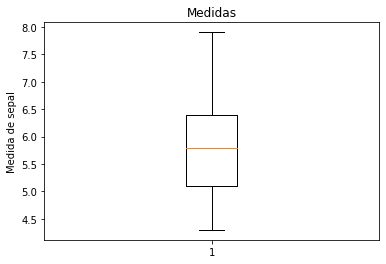

In [5]:
plt.boxplot(df["Sepal.Length"])
plt.ylabel("Medida de sepal")
plt.title("Medidas")

In [6]:
%matplotlib inline

<AxesSubplot:title={'center':'Medidas'}, xlabel='Sepal.Length', ylabel='Sepal.Width'>

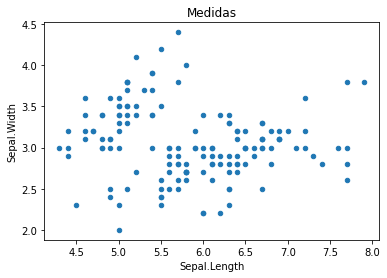

In [7]:
df.plot(kind="scatter",x="Sepal.Length",y="Sepal.Width",title="Medidas")


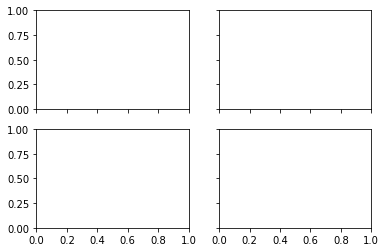

In [8]:
figure, axs = plt.subplots(2,2, sharey=True, sharex=True)

<AxesSubplot:xlabel='Sepal.Length', ylabel='Petal.Width'>

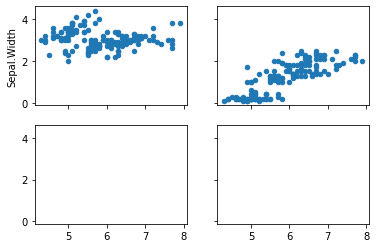

In [9]:
figure, axs = plt.subplots(2,2, sharey=True, sharex=True)
df.plot(kind="scatter",x="Sepal.Length",y="Sepal.Width",ax=axs[0][0])
df.plot(kind="scatter",x="Sepal.Length",y="Petal.Width",ax=axs[0][1])

<AxesSubplot:xlabel='Sepal.Length', ylabel='Petal.Length'>

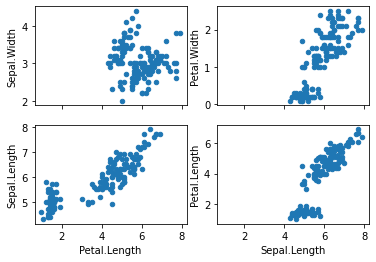

In [10]:
figure, axs = plt.subplots(2,2, sharey=False, sharex=True)
df.plot(kind="scatter",x="Sepal.Length",y="Sepal.Width",ax=axs[0][0])
df.plot(kind="scatter",x="Sepal.Length",y="Petal.Width",ax=axs[0][1])
df.plot(kind="scatter",x="Petal.Length",y="Sepal.Length",ax=axs[1][0])
df.plot(kind="scatter",x="Sepal.Length",y="Petal.Length",ax=axs[1][1])

In [11]:
#coeficioente de correlacion (coeficioente correlacion de pearson)
np.corrcoef(df["Sepal.Length"],df["Petal.Length"])

array([[1.        , 0.87175378],
       [0.87175378, 1.        ]])

In [12]:
np.corrcoef(df["Petal.Length"],df["Sepal.Length"])[0,1]

0.871753775886583

<AxesSubplot:xlabel='Petal.Length', ylabel='Sepal.Length'>

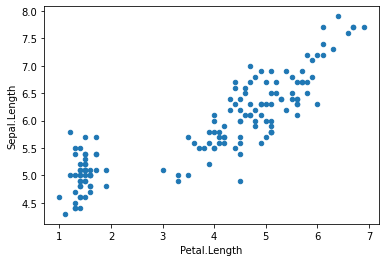

In [13]:
df.plot(kind="scatter",x="Petal.Length",y="Sepal.Length")

In [14]:
np.corrcoef(df["Petal.Length"],df["Petal.Width"])[0,1]

0.9628654314027963

<AxesSubplot:xlabel='Petal.Length', ylabel='Petal.Width'>

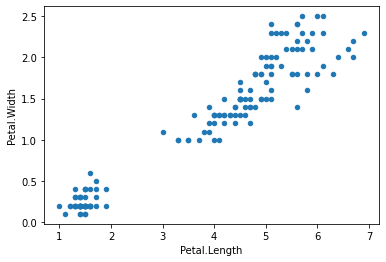

In [15]:
df.plot(kind="scatter",x="Petal.Length",y="Petal.Width")

In [16]:
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score

In [17]:
df["Petal.Length"].describe

<bound method NDFrame.describe of 0      1.4
1      1.4
2      1.3
3      1.5
4      1.4
      ... 
145    5.2
146    5.0
147    5.2
148    5.4
149    5.1
Name: Petal.Length, Length: 150, dtype: float64>

In [18]:
df["Petal.Width"].describe

<bound method NDFrame.describe of 0      0.2
1      0.2
2      0.2
3      0.2
4      0.2
      ... 
145    2.3
146    1.9
147    2.0
148    2.3
149    1.8
Name: Petal.Width, Length: 150, dtype: float64>

In [19]:
#regresion lineal
petal_X = df["Petal.Length"]
petal_y = df["Petal.Width"]

petal_X_train = petal_X.iloc[:-20].values
petal_X_test = petal_X.iloc[-20:].values

petal_y_train = petal_y.iloc[:-20].values
petal_y_test = petal_y.iloc[-20:].values

In [20]:
petal_X_train = petal_X_train.reshape(-1,1)
petal_X_test = petal_X_test.reshape(-1,1)

petal_y_train = petal_y_train.reshape(-1,1)
petal_y_test = petal_y_test.reshape(-1,1)

In [21]:
#creo modelo regresion lineal
modelo = linear_model.LinearRegression()

#entrenamos el modelo
modelo.fit(petal_X_train,petal_y_train)

#Creamos la prediccion
petal_y_pred = modelo.predict(petal_X_test)


20

In [22]:
petal_y_pred

array([[2.11872346],
       [2.23970992],
       [1.91707935],
       [1.71543523],
       [1.91707935],
       [2.11872346],
       [1.91707935],
       [1.87675052],
       [1.59444877],
       [1.8364217 ],
       [1.91707935],
       [1.71543523],
       [1.71543523],
       [2.03806581],
       [1.95740817],
       [1.75576406],
       [1.67510641],
       [1.75576406],
       [1.8364217 ],
       [1.71543523]])

In [23]:
print('Coeficientes: \n b1=', modelo.coef_, 'a=', modelo.intercept_)

Coeficientes: 
 b1= [[0.40328822]] a= [-0.34133469]


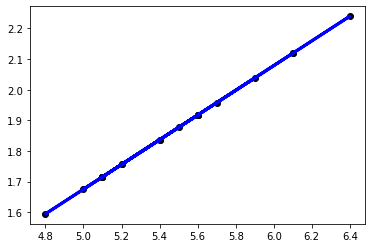

In [24]:
plt.scatter(petal_X_test,petal_y_pred,color='black')
plt.plot(petal_X_test,petal_y_pred,color='blue',linewidth=3)

In [25]:
# y = a + bx
x = 5.0
y = -0.34133469 + 0.40328822 * x
y

1.6751064099999997

In [26]:
df.tail()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Variety
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=b24b4ece-d489-43f0-9e2f-606f72c4649f' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>